In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# for k-NN stuff
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans 

In [9]:
path = '/Users/siobhankassem/Desktop/USC/Classes/Fall 2026/Python Data Science/Datasets/Waves_2023.txt'
waves = pd.read_csv(path, sep=r"\s+")

waves = waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]
waves = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)
waves

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5
...,...,...,...,...,...
17280,2.01,14.29,11.19,270,16.7
17281,1.75,15.38,10.37,267,16.7
17282,1.79,13.33,10.50,268,16.8
17283,1.66,14.29,10.32,271,16.8


In [11]:
def z_score(df):
    # subtract the column mean, then divide by the column standard deviation
    return (df - df.mean()) / df.std()

In [12]:
# now standardize the data
waves_z = z_score(waves) # 
waves_z.head()

,WVHT,DPD,APD,MWD,WTMP
0,0.166100,0.104602,0.499276,0.753178,-0.738984
1,0.242054,-0.097312,0.310355,0.818029,-0.738984
2,0.318007,0.104602,0.170014,0.731562,-0.738984
3,0.412949,-0.432925,0.304957,0.731562,-0.699994
4,0.450926,-0.432925,0.434503,0.731562,-0.661003


In [15]:
pca = PCA(n_components=5)
waves_scaled= pca.fit_transform(waves_z)

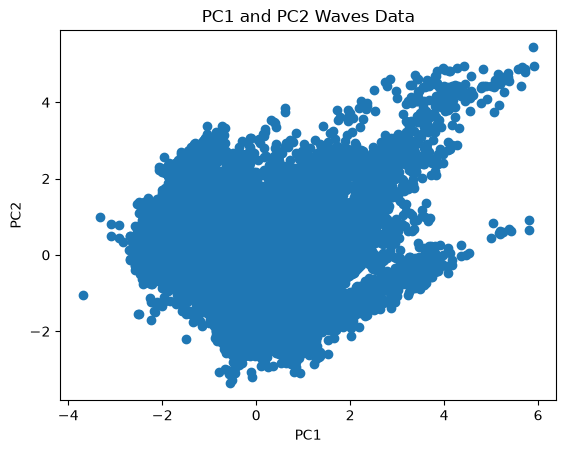

In [16]:
plt.subplots()
plt.scatter(waves_scaled[:, 0], waves_scaled[:, 1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PC1 and PC2 Waves Data')
plt.show()

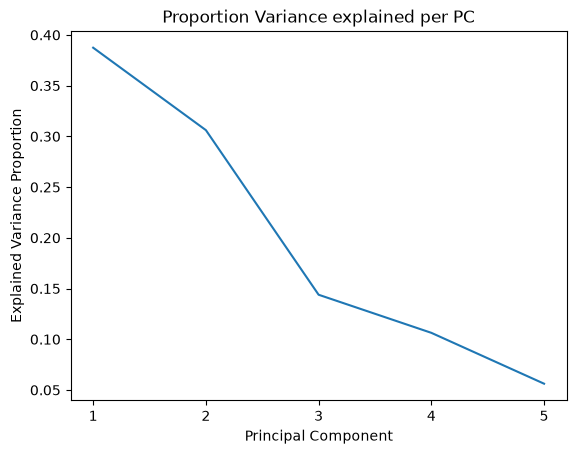

In [22]:
# The fraction of variance explained by each PC is stored in the fitted PCA object
variance_props = pca.explained_variance_ratio_[:5] 


xdata = range(1,len(variance_props)+1) # just so the graph doesnt start at 0 because python starts at 0.

plt.plot(xdata, variance_props)
plt.xticks(xdata)
plt.ylabel('Explained Variance Proportion')
plt.xlabel('Principal Component')
plt.title('Proportion Variance explained per PC')

plt.show()

PC 1 and 2 are needed to capture the most amount of variablity in the dataset because they have the highest amount of variance explained by their PC. Since 3 is at the elbow point, maybe 3 PCs are needed, but no more than that because the variance explained starts to decrease. 

In [25]:
num_pcs = 2

for pc in range(num_pcs):
    ranked_loadings = np.argsort(np.abs(pca.components_[pc]))[::-1][:5]
    print(f"Top 5 loadings for PC{pc+1}:")
    print(waves_z.columns[ranked_loadings])
    print("\n")

Top 5 loadings for PC1:
Index(['MWD', 'WVHT', 'WTMP', 'APD', 'DPD'], dtype='str')


Top 5 loadings for PC2:
Index(['DPD', 'APD', 'MWD', 'WVHT', 'WTMP'], dtype='str')




The most important variables are 'MWD', 'WVHT' for PC1 and 'DPD', 'APD' for PC2. All of the variables or loadings are the same for both PCs, but they are in differnt orders showing the different importances between each PC. 

Text(0, 0.5, 'Proportion of variance (%)')

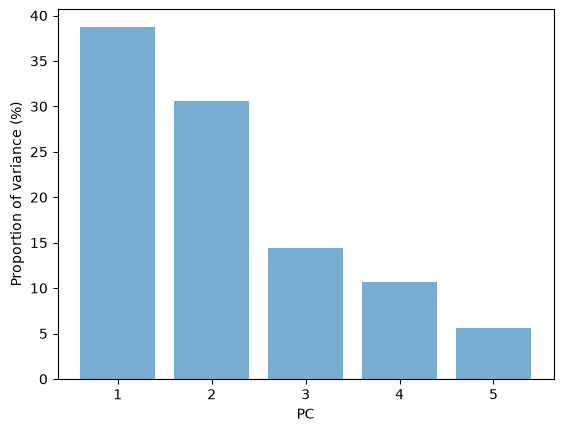

In [30]:
plt.bar(xdata, variance_props*100, alpha=0.6, align='center')
plt.xlabel("PC")
plt.ylabel("Proportion of variance (%)")

If the reduced dimensionality of a dataset isnt explaining the majority of variance in a dataset, then the method is doing a bad job. If the scree plot was flat and there was no elbow shape, then this would be an indication the the model was not reducing the data effectively. The limitations of dimensionality reduction would be shown if the scree plot was flat, since its not doing its job. This could be if the data is not linear and then the linear reduction does a bad job. 

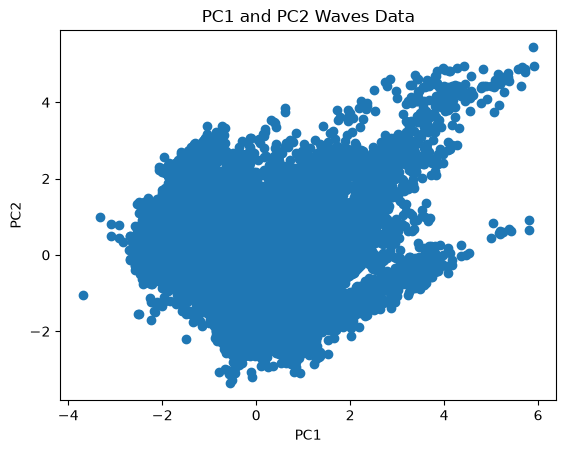

In [33]:
# same as before
plt.subplots()
plt.scatter(waves_scaled[:, 0], waves_scaled[:, 1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PC1 and PC2 Waves Data')
plt.show()

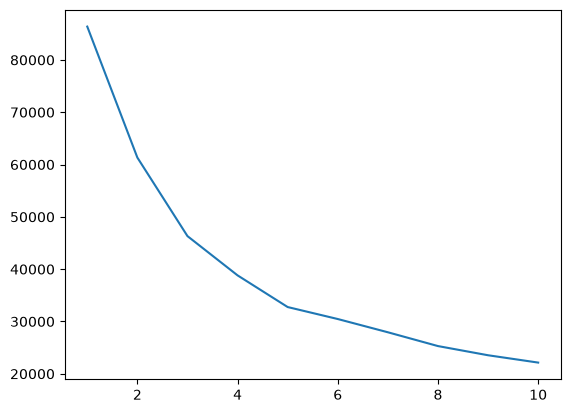

In [53]:
sum_squared_dist = []

for i in range(1,11):
    kmeans = KMeans(n_clusters=i, n_init="auto").fit(waves_scaled)
    sum_squared_dist.append(kmeans.inertia_)
    
plt.plot(range(1, 11), sum_squared_dist)

I think 5 clusters are the right amount of clusters because thats where it bends in the plot, and the sum of squared distances as an error plateus. 

In [60]:
kmeans_5 = KMeans(n_clusters=5, n_init="auto").fit(waves_scaled)
centers = kmeans.cluster_centers_
centers

array([[ 0.95635389,  1.433067  , -0.22720198, -1.0440613 , -0.02613316],
       [ 0.08508036, -1.59458012,  0.98734359, -0.2563586 ,  0.0118344 ],
       [-1.72204024,  0.26018357, -0.02201196,  0.45352282,  0.04456575],
       [ 2.79747278, -0.29627502,  0.3745624 ,  2.25087642, -0.00426658],
       [ 3.36433214,  3.13565139,  1.28520665,  0.69874075, -0.06020997],
       [ 1.82619829,  0.5355859 , -0.1924963 ,  0.41082629,  0.29044663],
       [-1.18439763,  1.52663735,  0.19984874,  0.00907497, -0.5585631 ],
       [ 0.03966735, -0.15464738,  0.39451611, -0.54748462,  0.28211308],
       [ 1.09398826, -1.25109849, -0.76586799, -0.00759657, -0.18849443],
       [-0.13651265,  0.09077592, -1.28539725,  0.0901548 ,  0.11075189]])

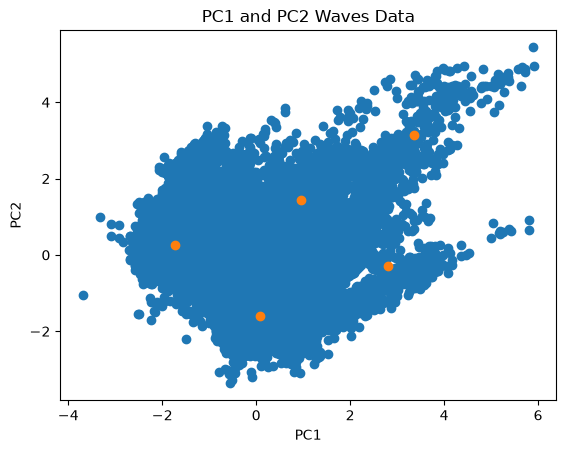

In [63]:
plt.subplots()
plt.scatter(waves_scaled[:, 0], waves_scaled[:, 1])
plt.scatter(centers[0:5, 0], centers[0:5, 1]) # grabs the first 
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PC1 and PC2 Waves Data')
plt.show()

Yes the clustering seems to make sense with my eyes. the shape kind of looks like a chicken or a hand print, and the orange clusters seem to be well spread out. 